In [113]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/paulajibola/consumer-finances/SCFP2019.csv


In [114]:
%pip install matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pickle
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats.mstats import trimmed_var
from sklearn.utils.validation import check_is_fitted
import warnings
# from teaching_tools.widgets import ClusterWidget, SCFClusterWidget

In [116]:
df = pd.read_csv("/kaggle/input/datasets/paulajibola/consumer-finances/SCFP2019.csv")

In [117]:
print("df_type:", type(df))
print("df shape:", df.shape)

df.head()

df_type: <class 'pandas.core.frame.DataFrame'>
df shape: (28885, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,6119.779308,2,75,6,12,4,2,0,...,5,3,6,3,2,10,6,6,3,3
1,1,12,4712.374912,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
2,1,13,5145.224455,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
3,1,14,5297.663412,2,75,6,12,4,2,0,...,5,2,6,2,1,10,4,4,2,2
4,1,15,4761.812371,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2


In [118]:
df.columns

Index(['YY1', 'Y1', 'WGT', 'HHSEX', 'AGE', 'AGECL', 'EDUC', 'EDCL', 'MARRIED',
       'KIDS',
       ...
       'NWCAT', 'INCCAT', 'ASSETCAT', 'NINCCAT', 'NINC2CAT', 'NWPCTLECAT',
       'INCPCTLECAT', 'NINCPCTLECAT', 'INCQRTCAT', 'NINCQRTCAT'],
      dtype='object', length=351)

In [119]:
df.describe()

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
count,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,...,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000,28885.000000
mean,2906.446945,29067.469448,4453.606750,1.223819,53.219837,3.388783,10.247395,3.073394,1.375974,0.748312,...,3.075022,3.654146,3.666713,3.666332,1.864532,6.717050,6.683157,6.713969,2.798823,2.809244
std,1678.234066,16782.340720,2815.046077,0.416809,16.243653,1.546648,2.700152,1.008865,0.484382,1.123829,...,1.509840,1.806267,1.858337,1.800673,0.794989,3.612269,3.532322,3.525801,1.168914,1.164626
min,1.000000,11.000000,1.442477,1.000000,18.000000,1.000000,-1.000000,1.000000,1.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1452.000000,14522.000000,2098.599956,1.000000,40.000000,2.000000,8.000000,2.000000,1.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,3.000000,4.000000,4.000000,2.000000,2.000000
50%,2906.000000,29063.000000,4761.795033,1.000000,54.000000,3.000000,11.000000,3.000000,1.000000,0.000000,...,3.000000,4.000000,4.000000,4.000000,2.000000,7.000000,7.000000,7.000000,3.000000,3.000000
75%,4359.000000,43594.000000,6179.113347,1.000000,65.000000,5.000000,12.000000,4.000000,2.000000,1.000000,...,5.000000,6.000000,6.000000,6.000000,3.000000,10.000000,10.000000,10.000000,4.000000,4.000000
max,5813.000000,58135.000000,14827.320644,2.000000,95.000000,6.000000,14.000000,4.000000,2.000000,7.000000,...,5.000000,6.000000,6.000000,6.000000,3.000000,12.000000,12.000000,12.000000,4.000000,4.000000


In [120]:
mask = df["TURNFEAR"] == 1
mask.sum()

np.int64(4623)

In [121]:
mask = df["TURNFEAR"] == 1
df_fear = df[mask]


print("df_fear type:", type(df_fear))
print("df_fear shape:", df_fear.shape)
df_fear.head()

df_fear type: <class 'pandas.core.frame.DataFrame'>
df_fear shape: (4623, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [122]:
age_groups = df_fear["AGECL"].unique()
print("Age groups:", age_groups)

Age groups: [3 5 1 2 4 6]


In [123]:
df_fear["AGECL"].head(10)

5      3
6      3
7      3
8      3
9      3
110    5
111    5
112    5
113    5
114    5
Name: AGECL, dtype: int64

In [124]:
df_fear["AGECL"].tail(10)

28860    4
28861    4
28862    4
28863    4
28864    4
28865    6
28866    6
28867    6
28868    6
28869    6
Name: AGECL, dtype: int64

In [125]:
agecl_dict = {
    1: "Under 35",
    2: "35-44",
    3: "45-54",
    4: "55-64",
    5: "65-74",
    6: "75 or Older",
}


age_cl = df_fear["AGECL"].replace(agecl_dict)
print("agecl type:", type(age_cl))
print("age_cl shape:", age_cl.shape)
age_cl.head(10)

agecl type: <class 'pandas.core.series.Series'>
age_cl shape: (4623,)


5      45-54
6      45-54
7      45-54
8      45-54
9      45-54
110    65-74
111    65-74
112    65-74
113    65-74
114    65-74
Name: AGECL, dtype: object

<Axes: title={'center': 'Credit Fearful: Age Groups'}, xlabel='Age Group', ylabel='Frequency [count]'>

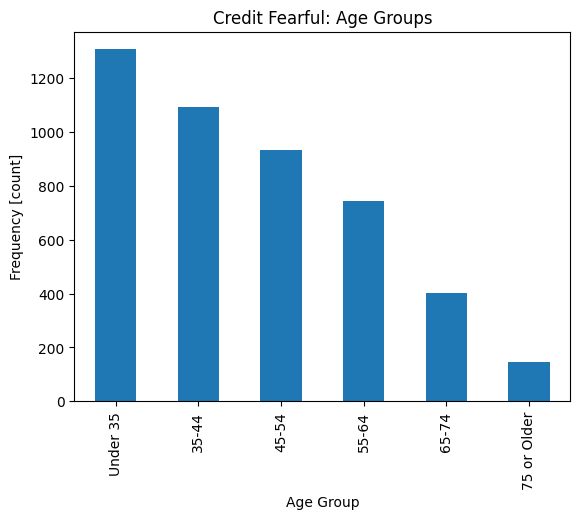

In [126]:
age_cl_value_counts = age_cl.value_counts()

age_cl_value_counts.plot(kind="bar", xlabel="Age Group", ylabel="Frequency [count]", title="Credit Fearful: Age Groups")

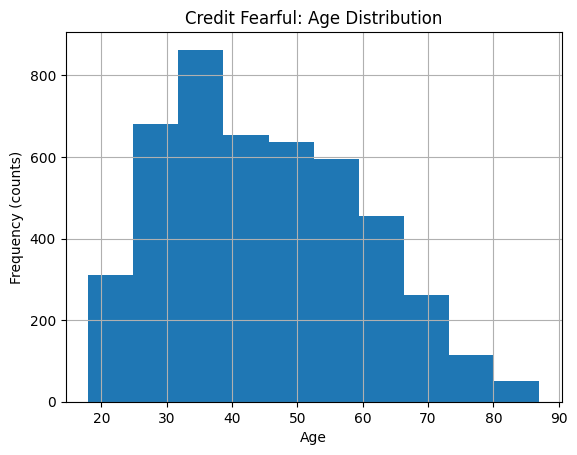

In [127]:
# plot histograms of "AGE"

df_fear["AGE"].hist(bins=10)
plt.xlabel("Age")
plt.ylabel("Frequency (counts)")
plt.title("Credit Fearful: Age Distribution");

Text(0.5, 1.0, 'Credit Fearful: Racial Groups')

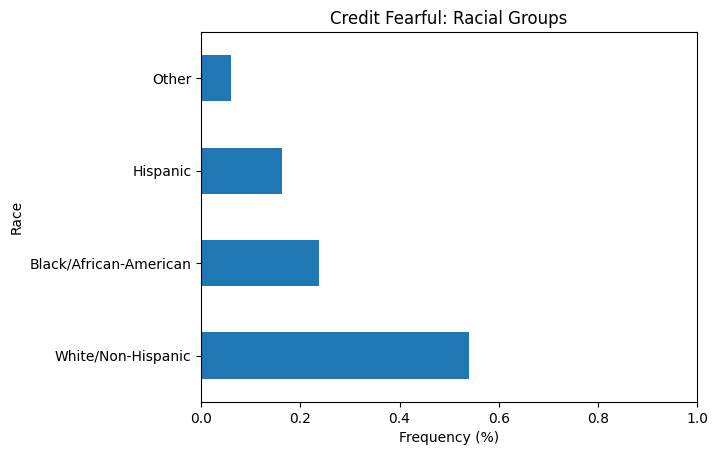

In [128]:
race_dict = {
    1: "White/Non-Hispanic",
    2: "Black/African-American",
    3: "Hispanic",
    5: "Other",
}


race = df_fear["RACE"].replace(race_dict)

race_value_counts = race.value_counts(normalize=True)
race_value_counts


race_value_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("Credit Fearful: Racial Groups")

Text(0.5, 1.0, 'SCF Respondents: Racial Groups')

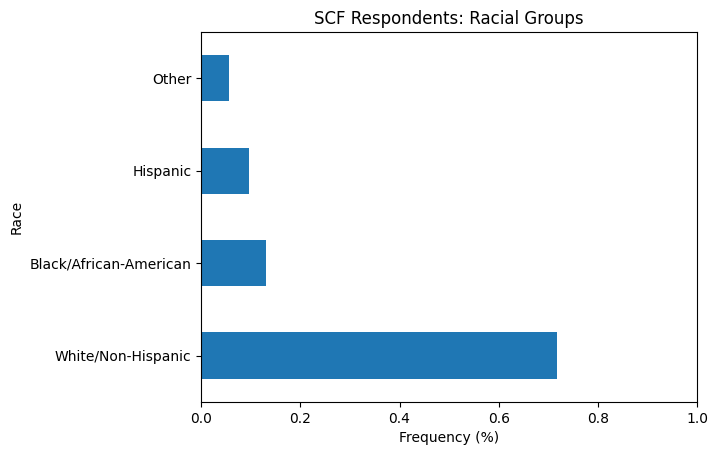

In [129]:
race = df["RACE"].replace(race_dict)
race_value_counts = race.value_counts(normalize=True)


race_value_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("SCF Respondents: Racial Groups")

In [130]:
inccat_dict = {
    1: "0-20",
    2: "21-39.9",
    3: "40-59.9",
    4: "60-79.9",
    5: "80-89.9",
    6: "90-100",
}


df_inccat = (
    df["INCCAT"]
    .replace(inccat_dict)
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)
    .rename("frequency")
    .to_frame()
    .reset_index()
)


print("df_inccat type:", type(df_inccat))
print("df_inccat shape:", df_inccat.shape)
df_inccat

df_inccat type: <class 'pandas.core.frame.DataFrame'>
df_inccat shape: (12, 3)


,TURNFEAR,INCCAT,frequency
0,0,90-100,0.297296
1,0,60-79.9,0.174841
2,0,40-59.9,0.143146
3,0,0-20,0.140343
4,0,21-39.9,0.135933
5,0,80-89.9,0.108441
6,1,0-20,0.288125
7,1,21-39.9,0.256327
8,1,40-59.9,0.228856
9,1,60-79.9,0.132598


In [131]:
asset_house_corr = df_fear["ASSET"].corr(df_fear["HOUSES"])

print("SCF: Asset Houses Correlation:", asset_house_corr)

SCF: Asset Houses Correlation: 0.583287973597916


In [132]:
cols = ["ASSET", "HOUSES", "INCOME", "DEBT", "EDUC"]
corr = df[cols].corr()

corr.head()
corr.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.519827,0.622429,0.261250,0.116673
HOUSES,0.519827,1.000000,0.247852,0.266661,0.169300
INCOME,0.622429,0.247852,1.000000,0.114646,0.069400
DEBT,0.261250,0.266661,0.114646,1.000000,0.054179
EDUC,0.116673,0.169300,0.069400,0.054179,1.000000


In [133]:
# import data by creating a wrangle function

def wrangle2(filepath):
    df = pd.read_csv(filepath)
    mask = (df["TURNFEAR"] == 1) & (df["NETWORTH"] < 2e6)
    df = df[mask]
    return df

In [134]:
df = wrangle2("/kaggle/input/datasets/paulajibola/consumer-finances/SCFP2019.csv")

In [135]:
df

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28865,5810,58101,8883.849940,1,84,6,13,4,1,0,...,3,3,4,3,1,8,5,5,2,2
28866,5810,58102,8968.383655,1,84,6,13,4,1,0,...,3,3,4,3,1,8,5,5,2,2
28867,5810,58103,9220.708616,1,84,6,13,4,1,0,...,3,3,4,3,1,8,5,5,2,2
28868,5810,58104,8927.245548,1,84,6,13,4,1,0,...,3,3,4,3,1,8,5,5,2,2


In [136]:
print("df type:", type(df))
print("df shape:", df.shape)
df.head()

df type: <class 'pandas.core.frame.DataFrame'>
df shape: (4418, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


In [137]:
# calculate variance, get 10 largest features

top_ten_var = df.var().sort_values().tail(10)

print("top_ten_var type:", type(top_ten_var))
print("top_ten_var shape:", top_ten_var.shape)
top_ten_var

top_ten_var type: <class 'pandas.core.series.Series'>
top_ten_var shape: (10,)


PLOAN1      1.140894e+10
ACTBUS      1.251892e+10
BUS         1.256643e+10
KGTOTAL     1.346475e+10
DEBT        1.848252e+10
NHNFIN      2.254163e+10
HOUSES      2.388459e+10
NETWORTH    4.847029e+10
NFIN        5.713939e+10
ASSET       8.303967e+10
dtype: float64

In [138]:
# create horizontal bar chart of `top_ten_var`

fig = px.bar(
    x=top_ten_var,
    y=top_ten_var.index,
    title="SCF: High Variance Features"
)


fig.update_layout(xaxis_title="Variance", yaxis_title="Feature")
fig.show()

In [139]:
# create a boxplot of 'Non-Home, Non-Financial Assets'

fig = px.box(
    data_frame=df,
    x="NHNFIN",
    title="Distribution of Non-home, Non-Financial Assets"
)

fig.update_layout(xaxis_title="Value [$]")
fig.show()

In [140]:
df["DEBT"].var()

18482520920.408085

In [141]:
# calculate trimmed variance
top_ten_trim_var = df.apply(trimmed_var, limits=(0.1, 0.1)).sort_values().tail(10)


print("top_ten_trim_var type:", type(top_ten_trim_var))
print("top_ten_trim_var shape:", top_ten_trim_var.shape)
top_ten_trim_var

top_ten_trim_var type: <class 'pandas.core.series.Series'>
top_ten_trim_var shape: (10,)


WAGEINC     5.550737e+08
HOMEEQ      7.338377e+08
NH_MORT     1.333125e+09
MRTHEL      1.380468e+09
PLOAN1      1.441968e+09
DEBT        3.089865e+09
NETWORTH    3.099929e+09
HOUSES      4.978660e+09
NFIN        8.456442e+09
ASSET       1.175370e+10
dtype: float64

In [142]:
# create horizontal bar chart of 'top_ten_trim_var'
# create horizontal bar chart of `top_ten_var`

fig = px.bar(
    x=top_ten_trim_var,
    y=top_ten_trim_var.index,
    title="SCF: High Variance Features"
)


fig.update_layout(xaxis_title="Variance", yaxis_title="Feature")
fig.show()

In [143]:
top_ten_trim_var.tail(5).index.to_list()

['DEBT', 'NETWORTH', 'HOUSES', 'NFIN', 'ASSET']

In [144]:
high_var_cols = top_ten_trim_var.tail(5).index.to_list()


print("high_var_cols type:", type(high_var_cols))
print("high_var_cols len:", len(top_ten_trim_var))
high_var_cols

high_var_cols type: <class 'list'>
high_var_cols len: 10


['DEBT', 'NETWORTH', 'HOUSES', 'NFIN', 'ASSET']

**SPLIT**

In [145]:
X = df[high_var_cols]

print("X type:", type(X))
print("X shape:", X.shape)
X.head()

X type: <class 'pandas.core.frame.DataFrame'>
X shape: (4418, 5)


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
5,12200.0,-6710.0,0.0,3900.0,5490.0
6,12600.0,-4710.0,0.0,6300.0,7890.0
7,15300.0,-8115.0,0.0,5600.0,7185.0
8,14100.0,-2510.0,0.0,10000.0,11590.0
9,15400.0,-5715.0,0.0,8100.0,9685.0


**BUILD MODEL**

**Iterate**

In [146]:
X_summary = X.aggregate(["mean", "std"]).astype(int)


# .aggregate() method is used to sum up one or more summary operations
# such as sum(), max(), min() or mean(), etc

print("X_summary type:", type(X_summary))
print("X_summary shape:", X_summary.shape)
X_summary

X_summary type: <class 'pandas.core.frame.DataFrame'>
X_summary shape: (2, 5)


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
mean,72701,76387,74530,117330,149089
std,135950,220159,154546,239038,288166


In [147]:
x = df["DEBT"]
print("mean:", round(x.mean()))
print("std:", round(x.std()))

mean: 72701
std: 135950


In [148]:
# instantiate transformer

ss = StandardScaler()

# transform `X`
X_scaled_data = ss.fit_transform(X)

# put `X_scaled_data` into DataFrame from nd.array
X_scaled = pd.DataFrame(X_scaled_data, columns=X.columns)


print("X_scaled type:", type(X_scaled))
print("X_scaled shape:", X_scaled.shape)
X_scaled.head()

X_scaled type: <class 'pandas.core.frame.DataFrame'>
X_scaled shape: (4418, 5)


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
0,-0.445075,-0.377486,-0.48231,-0.474583,-0.498377
1,-0.442132,-0.368401,-0.48231,-0.464541,-0.490047
2,-0.422270,-0.383868,-0.48231,-0.467470,-0.492494
3,-0.431097,-0.358407,-0.48231,-0.449061,-0.477206
4,-0.421534,-0.372966,-0.48231,-0.457010,-0.483818


In [149]:
X_scaled_summary = X_scaled.aggregate(["mean", "std"]).astype(int)

print("X_scaled_summary type:", type(X_scaled_summary))
print("X_scaled_suummary shape:", X_scaled_summary.shape)

X_scaled_summary

X_scaled_summary type: <class 'pandas.core.frame.DataFrame'>
X_scaled_suummary shape: (2, 5)


,DEBT,NETWORTH,HOUSES,NFIN,ASSET
mean,0,0,0,0,0
std,1,1,1,1,1


**Trian a K-Means model where n_clusers ranges from 2 to 12 (inclusive).**

In [150]:
n_clusters = range(2, 13)

inertia_errors = []
silhouette_scores = []

# add `for` loop to train model and calculate inertia, silhouette score
for k in n_clusters:
    # build model
    model = make_pipeline(StandardScaler(), KMeans(n_clusters=k, random_state=42))

    # train model
    model.fit(X)

    # access the fitted KMeans Object from the pipeline
    fitted_kmeans = model.named_steps['kmeans']

    # calculate inertia
    inertia_errors.append(fitted_kmeans.inertia_)

    # calculate silhouette score
    s_score = silhouette_score(X, fitted_kmeans.labels_)

    # calculate silhouette score
    silhouette_scores.append(s_score)


print("inertia_errors type:", type(inertia_errors))
print("inertia_errors len:", len(inertia_errors))
print("Inertia:", inertia_errors)
print()
print("silhouette_scores type:", type(silhouette_scores))
print("silhouette_scores len:", len(silhouette_scores))
print("Silhouette Scores:", silhouette_scores)

inertia_errors type: <class 'list'>
inertia_errors len: 11
Inertia: [11028.058082607175, 7190.703769068748, 6233.106346879298, 5009.683910188738, 4935.578599045223, 4282.331488864099, 4103.6585674172, 3503.109897216321, 2874.9614912020043, 2646.094394137889, 2505.471308202903]

silhouette_scores type: <class 'list'>
silhouette_scores len: 11
Silhouette Scores: [np.float64(0.7464502937083215), np.float64(0.7042841259119152), np.float64(0.7046977054481021), np.float64(0.6563064140490201), np.float64(0.6589817231149715), np.float64(0.6414988659227319), np.float64(0.6423235394675234), np.float64(0.6453132882450023), np.float64(0.6392046929708322), np.float64(0.6214410819897591), np.float64(0.6237975162108229)]


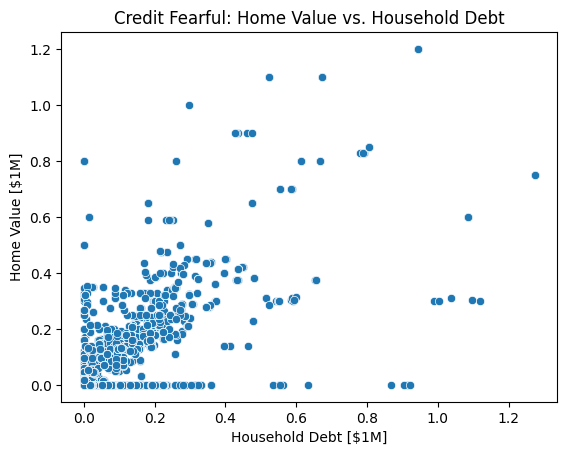

In [151]:
# plot 'HORSES' vs. 'DEBT'
sns.scatterplot(x=df["DEBT"] / 1e6, y=df["HOUSES"] / 1e6)

plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

In [152]:
# Split

X = df[["DEBT", "HOUSES"]]

print("X type:", type(X))
print("y type:", type(X))
X.head()

X type: <class 'pandas.core.frame.DataFrame'>
y type: <class 'pandas.core.frame.DataFrame'>


,DEBT,HOUSES
5,12200.0,0.0
6,12600.0,0.0
7,15300.0,0.0
8,14100.0,0.0
9,15400.0,0.0


In [153]:
# create line plot of `inertia_errors` vs. `n_clusters`

fig = px.line(
    x=n_clusters, y=inertia_errors, title="K-Means Model: Inertia vs Number of Clusters"
)

fig.update_layout(xaxis_title="Number of Cluster [K]", yaxis_title="Inertia")
fig.show()

In [154]:
# create a line of `silhouette_scores` vs. `n_clusters`

fig = px.line(
    x=n_clusters,
    y=silhouette_scores,
    title="K-Means Model: Silhouette Score vs Number of Clusters"
)

fig.update_layout(xaxis_title="Number of Clusters (k)", yaxis_title="Silhouette Score")

fig.show()

In [155]:
# build model
final_model = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=4, random_state=42)
)

# fit the model to data
final_model.fit(X)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=4, random_state=42))])

### communicating the results

In [156]:
labels = final_model.named_steps["kmeans"].labels_

print("labels type:", type(labels))
print("labels len:", len(labels))
print(labels[:5])

labels type: <class 'numpy.ndarray'>
labels len: 4418
[1 1 1 1 1]


In [157]:
xgb = X.groupby(labels).mean()

print("xgb type:", type(xgb))
print("xgb shape:", xgb.shape)

xgb

xgb type: <class 'pandas.core.frame.DataFrame'>
xgb shape: (4, 2)


,DEBT,HOUSES
0,135324.008683,175992.040521
1,19516.821072,7210.899183
2,762802.424242,820712.121212
3,315296.787709,362240.223464


In [158]:
# create side-by-side bar chart of `xgb`

fig = px.bar(
    xgb,
    barmode="group",
    title="Mean Household Finances by Cluster"
)

fig.update_layout(xaxis_title="Cluster", yaxis_title="Value [$]")
fig.show()

In [159]:
# instantiate transformer

pca = PCA(n_components=2, random_state=42)

# transform `X`
X_t = pca.fit_transform(X)

X_t

array([[-95979.87727589,   1762.51215904],
       [-95722.11892362,   2068.38898365],
       [-93982.2500458 ,   4133.05754978],
       ...,
       [-55081.72647693, -35055.7069889 ],
       [-55081.72647693, -35055.7069889 ],
       [-55081.72647693, -35055.7069889 ]])

In [160]:
# put it back into a dataframe

X_pca = pd.DataFrame(X_t, columns=["PC1", "PC2"])

print("X_pca type:", type(X_pca))
print("X_pca shape:", X_pca.shape)

X_pca.head()

X_pca type: <class 'pandas.core.frame.DataFrame'>
X_pca shape: (4418, 2)


,PC1,PC2
0,-95979.877276,1762.512159
1,-95722.118924,2068.388984
2,-93982.250046,4133.057550
3,-94755.525103,3215.427076
4,-93917.810458,4209.526756


In [161]:
labels_pd = pd.Series(labels)

In [162]:
new_labels = labels_pd.sort_values().astype(str)    # convert the values of the labels into strings so the labels do not present as continuous variables, rather they present as categorical variables

In [163]:
# create scatter plot of `PC1` and `PC2`

fig = px.scatter(
    data_frame=X_pca,
    x="PC1",
    y="PC2",
    color=labels.astype(str),    # to convert continous variable to categorical variable
    title="PCA Representation of Clusters"
)


fig.update_layout(xaxis_title="Value [$]", yaxis_title="Cluster")
fig.show()